# Etapa 6 - Canasta comparable y conclusiones finales

**Proyecto:** Comparación de precios y promociones - DIA vs. Carrefour  
**Fuente:** SEPA, julio de 2026  
**Universo principal:** 2.220 productos comunes a las dos cadenas, con cobertura completa en siete provincias.

**Objetivo:** comparar los precios por categoría, calcular el costo de una canasta de productos idénticos y reunir los principales hallazgos del proyecto.

> **Alcance:** la canasta utiliza una unidad comercial de cada producto seleccionado, sin ponderaciones de consumo. Los precios son promedios consolidados del universo principal, no precios de un local específico ni una canasta básica oficial.

## Organización

1. Alcance metodológico  
2. Carga de productos  
3. Comparación general y por categorías  
4. Selección manual de la canasta  
5. Costo total de la canasta  
6. Comparación producto por producto  
7. Sensibilidad del resultado  
8. Resultados anteriores relevantes  
9. Conclusiones generales  
10. Cierre y documentación

## 1. Alcance metodológico

Se utiliza el universo principal de **2.220 productos idénticos entre DIA y Carrefour**, con cobertura en **siete provincias**. En la Etapa 3 se definió este universo como referencia principal: mantener siete provincias permitió incorporar **558 productos adicionales** frente al universo de ocho provincias (1.662 artículos), cuya cobertura en Jujuy era más limitada.

Para cada producto se comparan los **precios efectivos medios consolidados** de DIA y Carrefour, generados en las etapas anteriores. La comparación conserva la misma composición de productos en ambas cadenas y evita diferencias debidas a surtidos distintos. **No implica que cada provincia o sucursal tenga el mismo peso estadístico:** los precios ya estaban consolidados a partir de las observaciones disponibles.

El universo de **1.662 productos de ocho provincias** solo se retomará al presentar resultados históricos de la Etapa 3; **no interviene en los cálculos nuevos de esta etapa**. Todos los resultados son descriptivos de los datos SEPA de julio de 2026.

## 2. Carga y revisión del dataset

El archivo de la Etapa 5 contiene los 2.220 productos y sus categorías finales. Se utilizará `df_productos` durante toda la etapa. Las rutas son relativas a la carpeta `notebooks/`, igual que en los notebooks anteriores.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

# Colores corporativos del proyecto
COLOR_DIA = "#AF1913"         
COLOR_CARREFOUR = "#133EB4"   

COLORES_CADENAS = {'DIA': COLOR_DIA,'CARREFOUR': COLOR_CARREFOUR}

# Configuración visual
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

RUTA_FIGURAS = Path('../outputs/figures')
RUTA_TABLAS = Path('../outputs/tables')

RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
RUTA_TABLAS.mkdir(parents=True, exist_ok=True)

# Universo principal de la Etapa 6
df_productos = pd.read_parquet('../data/processed/productos_media_y_categorizados.parquet')
df_productos['id_producto'] = df_productos['id_producto'].astype('string').str.strip()

assert len(df_productos) == 2220
assert df_productos['id_producto'].is_unique
assert df_productos[['precio_medio_dia', 'precio_medio_carrefour', 'categoria']].notna().all().all()

display(df_productos.head())
print('Productos:', len(df_productos))
print('Categorías:', df_productos['categoria'].nunique())

,id_producto,descripcion_carrefour,precio_medio_carrefour,precio_medio_dia,categoria
0,40084107,HUEVO CHOCOLATE SORPRESA CELESTE KINDER X 20 GRS,2875.50,2793.33,ALIMENTOS
1,42277057,CREMA FACIAL CUIDADO NUTRITIVO NIVEA CARE X 100CC,7872.42,6455.00,PERFUMERIA Y LIMPIEZA
2,75079437,ANTITRANSP FEM CREMA CLINICAL SOFT DOVE X 58GRS,18265.21,12750.00,PERFUMERIA Y LIMPIEZA
3,75082734,ANTITRANSPIRANTE BARRA ORIGINAL DOVE X 53 GR,7906.62,8037.19,PERFUMERIA Y LIMPIEZA
4,75083694,DESODORANTE STICK BLUE LAVENDER AXE X 58 GRM,8677.08,8718.77,PERFUMERIA Y LIMPIEZA


Productos: 2220
Categorías: 5


## 3. Comparación general y por categorías

### 3.1 Precio medio general - 2.220 productos comunes

Antes de estudiar las categorías y la canasta, se compara el **precio medio de los 2.220 artículos idénticos** en DIA y Carrefour, utilizando el universo principal de **siete provincias**.

El indicador se calcula como el promedio simple de los precios efectivos medios consolidados de los productos de cada cadena. Así, **cada producto tiene el mismo peso en el promedio**, independientemente de su precio o categoría. También se cuenta cuántos artículos presentan menor precio en cada cadena.

La diferencia porcentual toma como referencia el precio medio de Carrefour. Este análisis mide el **nivel medio de precios del catálogo comparable**; no representa el costo de una compra habitual, una canasta ponderada ni el precio de una sucursal específica.

In [62]:
# Comparación general sobre los 2.220 productos del universo principal
resumen_general = df_productos[['precio_medio_dia', 'precio_medio_carrefour']].mean()

precio_general_dia = resumen_general['precio_medio_dia']
precio_general_carrefour = resumen_general['precio_medio_carrefour']
diferencia_general_pct = (precio_general_dia - precio_general_carrefour) / precio_general_carrefour * 100

dia_mas_barato = (df_productos['precio_medio_dia'] < df_productos['precio_medio_carrefour']).sum()
carrefour_mas_barato = (df_productos['precio_medio_carrefour'] < df_productos['precio_medio_dia']).sum()

print(f'Precio medio DIA: ${precio_general_dia:,.2f}')
print(f'Precio medio Carrefour: ${precio_general_carrefour:,.2f}')
print(f'Diferencia DIA - Carrefour: {diferencia_general_pct:+.2f}%')
print(f'Productos más baratos en DIA: {dia_mas_barato}')
print(f'Productos más baratos en Carrefour: {carrefour_mas_barato}')

Precio medio DIA: $5,102.43
Precio medio Carrefour: $5,416.17
Diferencia DIA - Carrefour: -5.79%
Productos más baratos en DIA: 1330
Productos más baratos en Carrefour: 890


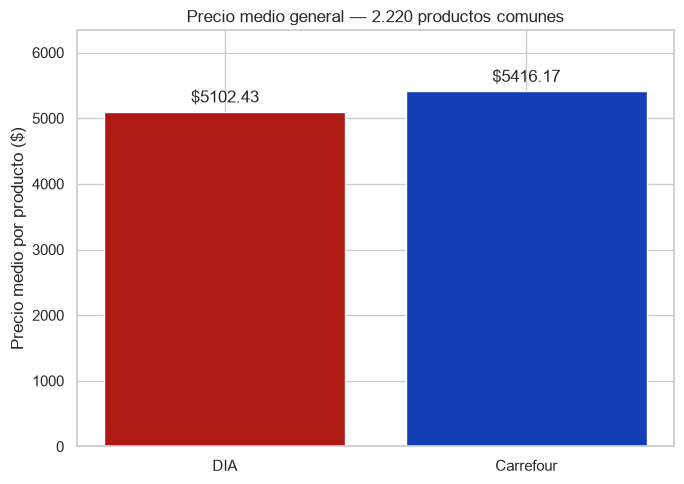

In [63]:
# Gráfico del precio medio general por cadena
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(['DIA', 'Carrefour'], [precio_general_dia, precio_general_carrefour], color=[COLOR_DIA, COLOR_CARREFOUR])
ax.bar_label(barras, fmt='$%.2f', padding=4)
ax.set_ylabel('Precio medio por producto ($)')
ax.set_title('Precio medio general — 2.220 productos comunes')
ax.set_ylim(0, max(precio_general_dia, precio_general_carrefour) * 1.17)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_precio_medio_general.png', dpi=200, bbox_inches='tight')
plt.show()

Sobre los **2.220 productos comunes**, el precio medio es **aproximadamente $5.102 en DIA y $5.416 en Carrefour**. La diferencia relativa entre ambas medias ronda el **-5,79 %**, favorable a DIA. Asimismo, DIA ofrece un precio inferior en **1.330 artículos (59,91 %)**, mientras que Carrefour lo hace en **890 (40,09 %)**.

Este resultado describe el nivel medio de precios del **mismo conjunto de artículos** en las dos cadenas, sin diferencias de composición. Sin embargo, no puede interpretarse como un ahorro equivalente para cualquier compra: una canasta concreta puede incluir solo una parte del universo y su diferencia dependerá de los productos seleccionados.


### 3.2 Comparación por categorías

Las cinco categorías fueron definidas manualmente en la Etapa 4 y completadas con NLP/ML en la Etapa 5. Su propósito en esta sección es describir cómo se distribuyen las diferencias de precios **entre los mismos productos de cada categoría**; **no se utilizaron para decidir qué productos integran la canasta**.

La diferencia entre precios medios toma a Carrefour como referencia:

`(precio medio DIA − precio medio Carrefour) / precio medio Carrefour × 100`

Una diferencia negativa indica menor precio medio en DIA. Los porcentajes de productos más baratos se calculan artículo por artículo y responden una pregunta diferente. Las medias por categoría no representan el costo de una compra habitual ni están ponderadas por cantidades consumidas.

In [64]:
# Diferencias por producto: DIA respecto de Carrefour
df_productos['diferencia_abs'] = df_productos['precio_medio_dia'] - df_productos['precio_medio_carrefour']
df_productos['diferencia_pct'] = df_productos['diferencia_abs'] / df_productos['precio_medio_carrefour'] * 100

df_productos['dia_mas_barato'] = df_productos['diferencia_abs'] < 0
df_productos['carrefour_mas_barato'] = df_productos['diferencia_abs'] > 0

resumen_categorias = df_productos.groupby('categoria').agg(
    productos=('id_producto', 'count'),
    precio_medio_dia=('precio_medio_dia', 'mean'),
    precio_medio_carrefour=('precio_medio_carrefour', 'mean'),
    pct_dia_mas_barato=('dia_mas_barato', 'mean'),
    pct_carrefour_mas_barato=('carrefour_mas_barato', 'mean'),
).reset_index()

resumen_categorias['diferencia_medias_pct'] = (
    (resumen_categorias['precio_medio_dia'] - resumen_categorias['precio_medio_carrefour'])
    / resumen_categorias['precio_medio_carrefour'] * 100
)
resumen_categorias[['pct_dia_mas_barato', 'pct_carrefour_mas_barato']] *= 100

display(resumen_categorias.round(2))

,categoria,productos,precio_medio_dia,precio_medio_carrefour,pct_dia_mas_barato,pct_carrefour_mas_barato,diferencia_medias_pct
0,ALIMENTOS,1074,3787.23,4010.55,64.99,35.01,-5.57
1,BEBIDAS,380,5184.06,5636.78,67.11,32.89,-8.03
2,MASCOTAS,38,11997.36,11934.21,23.68,76.32,0.53
3,OTROS,14,4714.08,4599.98,28.57,71.43,2.48
4,PERFUMERIA Y LIMPIEZA,714,6677.96,7082.20,50.98,49.02,-5.71


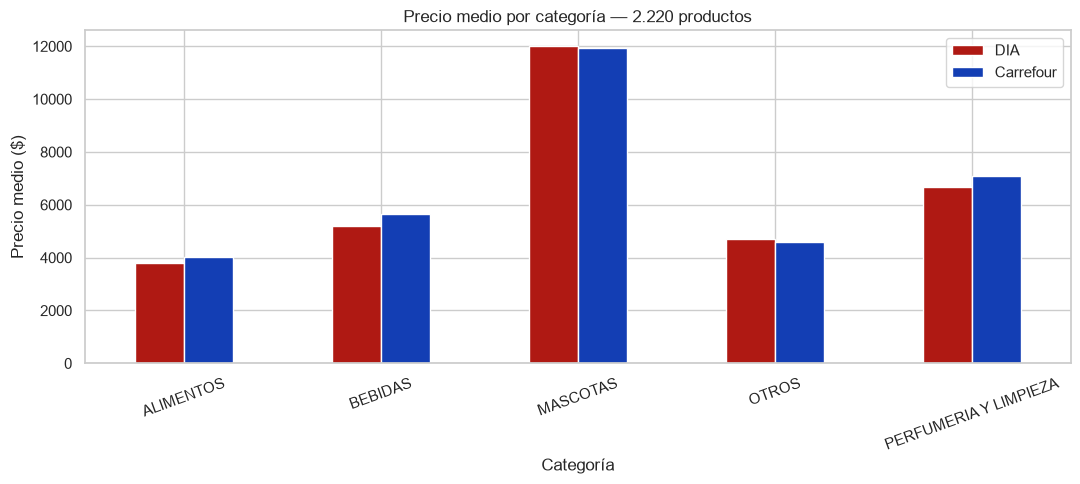

In [65]:
# Precio medio por producto en cada categoría
resumen_categorias.plot(
    x='categoria',
    y=['precio_medio_dia', 'precio_medio_carrefour'],
    kind='bar', figsize=(11, 5), rot=20, color=[COLOR_DIA, COLOR_CARREFOUR]
)
plt.title('Precio medio por categoría — 2.220 productos')
plt.xlabel('Categoría')
plt.ylabel('Precio medio ($)')
plt.legend(['DIA', 'Carrefour'])
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_precio_medio_categorias.png', dpi=200, bbox_inches='tight')
plt.show()

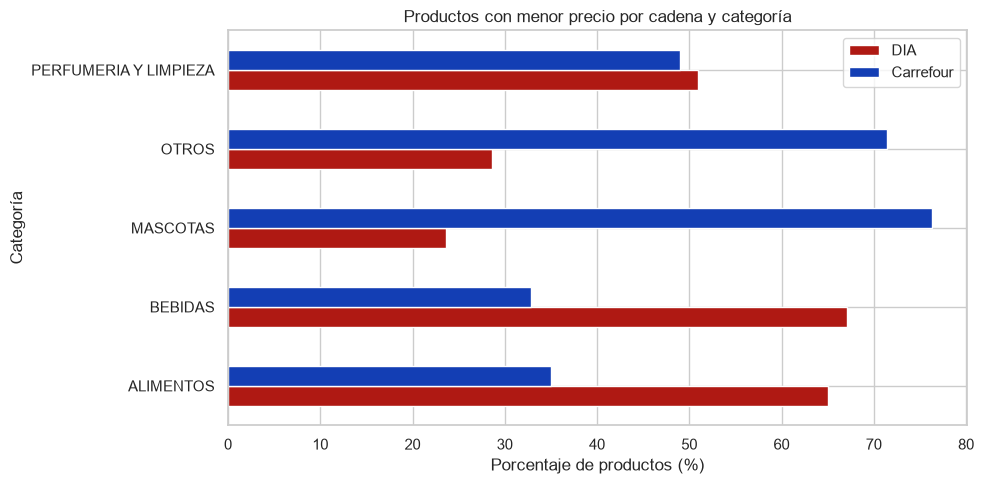

In [66]:
# Porcentaje de productos más baratos en cada cadena, por categoría
resumen_categorias.plot(
    x='categoria',
    y=['pct_dia_mas_barato', 'pct_carrefour_mas_barato'],
    kind='barh', figsize=(10, 5), color=[COLOR_DIA, COLOR_CARREFOUR]
)
plt.title('Productos con menor precio por cadena y categoría')
plt.xlabel('Porcentaje de productos (%)')
plt.ylabel('Categoría')
plt.legend(['DIA', 'Carrefour'])
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_productos_mas_baratos_categoría.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación de la comparación por categorías**

El análisis muestra que DIA presenta un precio medio inferior en las tres categorías con mayor cantidad de productos: **BEBIDAS (-8,03 %; 380 artículos)**, **PERFUMERIA Y LIMPIEZA (-5,71 %; 714 artículos)** y **ALIMENTOS (-5,57 %; 1.074 artículos)**. La ventaja más pronunciada en términos de diferencia entre medias se observa en bebidas.

Al evaluar cada producto por separado, DIA tiene menor precio en el **67,11 % de las bebidas** y en el **64,99 % de los alimentos**. En perfumería y limpieza la distribución es mucho más equilibrada (**50,98 %** favorables a DIA), aunque la diferencia entre las medias de precios favorece a esa cadena. Esto indica que el valor y la cantidad de artículos más baratos son medidas complementarias: **no basta con contar productos para determinar la magnitud de la diferencia de precios**.

En **MASCOTAS (38 productos)** y **OTROS (14 productos)**, el precio medio resulta ligeramente inferior en Carrefour (DIA registra diferencias de **+0,53 %** y **+2,48 %**, respectivamente). Estos grupos contienen pocos artículos y algunas categorías fueron asignadas mediante clasificación automática, por lo que sus conclusiones requieren mayor cautela.

En todos los casos se comparan los mismos artículos de ambas cadenas dentro de cada categoría. Sin embargo, las categorías agrupan productos de distintos precios y presentaciones, por lo que sus medias son **indicadores descriptivos**, no costos de una canasta representativa.

## 4. Selección manual de la canasta

### 4.1 Procedimiento utilizado

A partir de los **2.220 productos**, se generó un Excel auxiliar con solo `id_producto` y `descripcion_carrefour`. La selección se realizó **manualmente viendo únicamente las descripciones**, sin acceso a los precios ni a la cadena más económica. Esto reduce el sesgo de selección vinculado al conocimiento de los precios, aunque no elimina la subjetividad de la selección intencional.

Se eligieron **33 productos de consumo cotidiano** con sus presentaciones comerciales específicas. Se considera **una unidad comercial de cada producto**: por ejemplo, un paquete «3 × 90 g» cuenta como un solo paquete. No se asignan cantidades adicionales ni se utilizan ponderaciones de consumo.

La lista definitiva se guardó en `data/processed/canasta_seleccionada.xlsx` con **dos columnas**: `id_producto` y `descripcion_carrefour`. La hoja **no tiene precios**, porque estos se recuperan del Parquet mediante el identificador.

La canasta es **exploratoria**: no equivale a la canasta básica oficial, a una dieta nutricionalmente completa ni a una muestra representativa de los hogares.

### 4.2 Catálogo utilizado para elegir

La siguiente celda muestra cómo se construyó el catálogo original. La exportación está **comentada** porque la selección ya fue realizada; ejecutarla no genera archivos nuevos.

In [67]:
df_catalogo = df_productos[['id_producto', 'descripcion_carrefour']].sort_values('descripcion_carrefour')

# Exportación realizada durante la selección manual (desactivada por ahora):
# df_catalogo.to_excel('../data/processed/catalogo_seleccion_canasta.xlsx', index=False)

display(df_catalogo.head())

,id_producto,descripcion_carrefour
417,7790070265333,ACEITE AEROSOL GIRASOL CLASICO FRITOLIM X120 GRS
1485,7792180137944,ACEITE DE GIRASOL PUREZA PET 1.5 LT
606,7790199604174,ACEITE DE OLIVA EXTRA VIRGEN MORIXE VIDRIO X 5...
1466,7792180001665,ACEITE GIRASOL CANUELAS PET X 1.5 LT
1465,7792180001641,ACEITE GIRASOL CANUELAS PET X 900 CC


### 4.3 Cargar e integrar la selección

Leemos directamente el Excel definitivo desde `data/processed/` y recuperamos los precios con un `merge` por `id_producto`, igual que en las etapas anteriores. No hace falta columna `cantidad`, funciones auxiliares ni condicionales que salteen celdas.

In [68]:
# Canasta ya seleccionada manualmente
# dtype=str conserva los identificadores tal como aparecen en el archivo.
df_seleccion = pd.read_excel(
    '../data/processed/canasta_seleccionada.xlsx',
    dtype={'id_producto': 'string'}
)
df_seleccion['id_producto'] = df_seleccion['id_producto'].str.strip()

assert len(df_seleccion) == 33
assert df_seleccion['id_producto'].is_unique

# La descripción queda tomada del Excel; los precios provienen del dataset principal.
df_canasta = df_seleccion[['id_producto', 'descripcion_carrefour']].merge(
    df_productos[['id_producto', 'categoria', 'precio_medio_dia', 'precio_medio_carrefour']],
    on='id_producto',
    how='left',
    validate='one_to_one'
)

assert df_canasta[['precio_medio_dia', 'precio_medio_carrefour']].notna().all().all()

display(df_canasta)

,id_producto,descripcion_carrefour,categoria,precio_medio_dia,precio_medio_carrefour
0,7790070562258,HARINA DE TRIGO 000 C VITAMINAS FAVORITA X 1 KG,ALIMENTOS,1194.36,1186.60
1,7790070411914,ARROZ YAMANI INTEGRAL GALLO CAJA X 500 GRS,ALIMENTOS,3309.86,3319.94
2,7790070336149,FIDEOS MOSTACHOLES N52 RAYADO LUCCHETTI X 500 GRS,ALIMENTOS,1701.71,1673.63
3,7790580138721,POLENTA INSTANTAN PRESTOPRONTA BOLSA X 730 GRS,ALIMENTOS,2305.86,2348.75
4,7790199604587,AVENA TRADICIONAL MORIXE X 400 GRS,ALIMENTOS,2206.58,2248.06
5,7790580132453,LENTEJAS SECAS REMOJADAS ARCOR LATA X 300 GRS,ALIMENTOS,1749.23,1533.91
6,7793360132384,ARVEJAS SECAS REMOJADAS LA CAMPAGNOLA X 300 GRS,ALIMENTOS,1412.19,1395.64
7,7790272001029,ACEITE GIRASOL NATURA PET X 1.5 LT,ALIMENTOS,6880.94,6580.81
8,7790580138868,PURE DE TOMATE LA CAMPAGNOLA TETRA X 530 GRM,ALIMENTOS,1165.00,1421.48
9,7790580567101,TOMATE PERITA CUBETEADO ARCOR LATA X 400 GRS,ALIMENTOS,1808.39,1592.02


## 5. Comparación del costo de la canasta

### 5.1 Costo consolidado de la canasta

Como se seleccionó **una unidad comercial por artículo**, el costo total se obtiene **sumando** los precios medios de los 33 productos, sin multiplicarlos por ninguna cantidad. La diferencia porcentual se expresa respecto de Carrefour.

El resultado es un **costo sintético** construido con precios medios consolidados: no equivale al ticket de compra de una sucursal específica.

In [69]:
costo_dia = df_canasta['precio_medio_dia'].sum()
costo_carrefour = df_canasta['precio_medio_carrefour'].sum()

diferencia_canasta_abs = costo_dia - costo_carrefour
diferencia_canasta_pct = diferencia_canasta_abs / costo_carrefour * 100

print(f'Costo total DIA: ${costo_dia:,.2f}')
print(f'Costo total Carrefour: ${costo_carrefour:,.2f}')
print(f'Diferencia DIA - Carrefour: ${diferencia_canasta_abs:,.2f} ({diferencia_canasta_pct:+.2f}%)')

Costo total DIA: $147,749.30
Costo total Carrefour: $150,381.92
Diferencia DIA - Carrefour: $-2,632.62 (-1.75%)


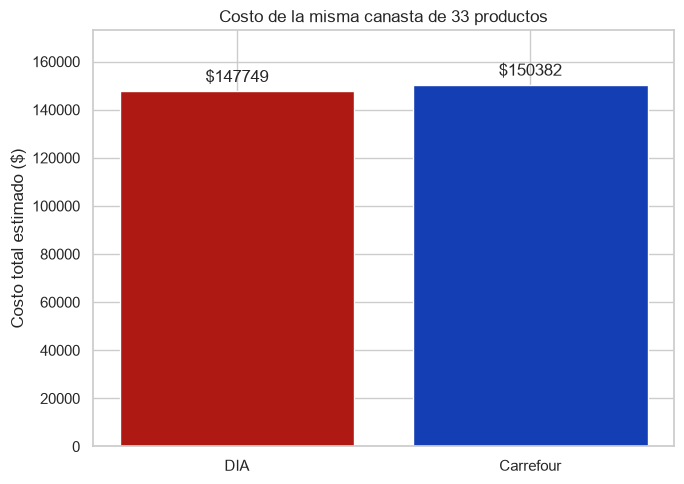

In [70]:
# Gráfico principal de la canasta
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(['DIA', 'Carrefour'], [costo_dia, costo_carrefour], color=[COLOR_DIA, COLOR_CARREFOUR])
ax.bar_label(barras, fmt='$%.0f', padding=4)
ax.set_ylabel('Costo total estimado ($)')
ax.set_title('Costo de la misma canasta de 33 productos')
ax.set_ylim(0, max(costo_dia, costo_carrefour) * 1.15)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_costo_total_canasta.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación del costo total de la canasta**

El costo de adquirir **una unidad comercial de cada uno de los 33 artículos seleccionados** es de **$147.749,30 en DIA** y **$150.381,92 en Carrefour**. Por lo tanto, la canasta presenta una diferencia de **$2.632,62 (-1,75 %)** a favor de DIA, utilizando como referencia el costo en Carrefour.

El resultado corresponde a una **selección manual definida sin consultar precios**, cuyos artículos fueron identificados mediante `id_producto`. No debe confundirse con el costo de una compra real en una sucursal ni extrapolarse a todas las combinaciones posibles de productos.

### 5.2 Comparación provincial del costo de la canasta

Para incorporar la dimensión territorial, se calcula el costo de los mismos **33 productos seleccionados** en las siete provincias del universo principal.

Se utiliza el archivo `precios_producto_provincia_7.parquet`, generado en la Etapa 3, que contiene el precio efectivo medio de cada producto por provincia y cadena.

El costo provincial se obtiene sumando los precios medios de una unidad comercial de cada artículo. De esta manera, la composición de la canasta permanece constante y las diferencias observadas corresponden a los precios provinciales de los productos seleccionados.

Los valores representan costos hipotéticos construidos a partir de precios medios, no compras realizadas en una sucursal específica.

In [71]:
# Precios medios por producto, provincia y cadena
df_precios_prov = pd.read_parquet('../data/processed/precios_producto_provincia_7.parquet')
df_precios_prov['id_producto'] = df_precios_prov['id_producto'].astype('string')

# Seleccionamos los mismos 33 productos de la canasta
df_canasta_prov = df_precios_prov.merge(df_canasta[['id_producto']], on='id_producto', how='inner')

# Verificamos 33 productos por provincia y cadena
cobertura = df_canasta_prov.groupby(['provincia', 'cadena'])['id_producto'].nunique()

assert len(cobertura) == 14
assert cobertura.eq(33).all()

# Costo total por provincia y cadena
df_costos_prov = (df_canasta_prov.groupby(['provincia', 'cadena'])['precio_efectivo_medio'] .sum() .unstack('cadena'))

df_costos_prov['diferencia_abs'] = df_costos_prov['DIA'] - df_costos_prov['CARREFOUR']
df_costos_prov['diferencia_pct'] = df_costos_prov['diferencia_abs'] / df_costos_prov['CARREFOUR'] * 100

display(df_costos_prov.round(2))

cadena,CARREFOUR,DIA,diferencia_abs,diferencia_pct
provincia,,,,
BUENOS AIRES,147620.77,147505.48,-115.29,-0.08
CABA,152890.39,148168.62,-4721.77,-3.09
CORDOBA,147812.15,145949.00,-1863.15,-1.26
CORRIENTES,150096.66,146169.00,-3927.67,-2.62
ENTRE RIOS,142706.07,145974.38,3268.31,2.29
SALTA,145771.27,151384.50,5613.23,3.85
SANTA FE,144207.00,145949.00,1742.00,1.21


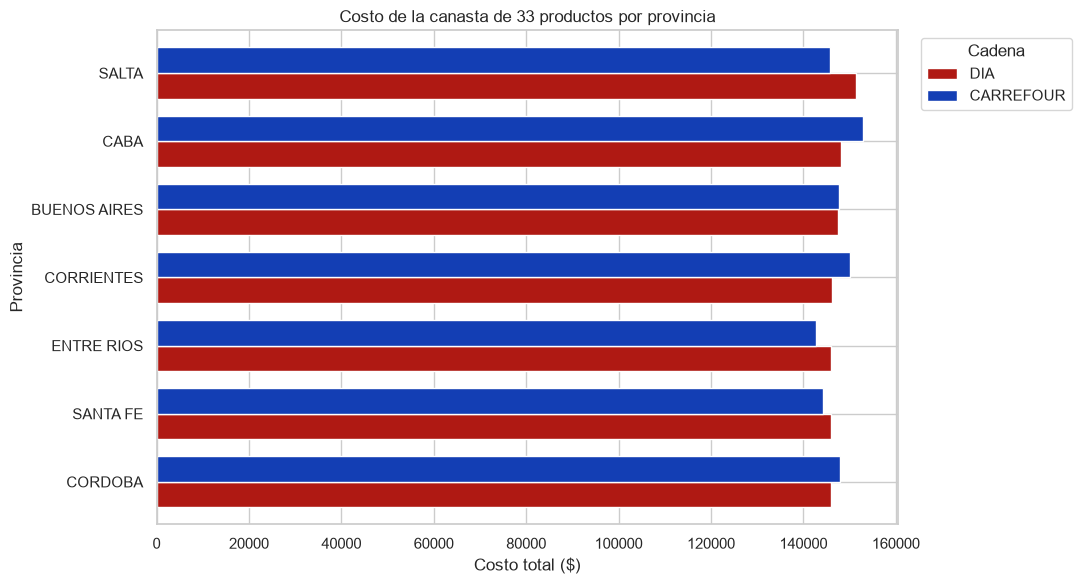

In [72]:
ax = (df_costos_prov[['DIA', 'CARREFOUR']].sort_values('DIA').plot(kind='barh', figsize=(11, 6), width=0.75, color=[COLOR_DIA, COLOR_CARREFOUR]))

ax.set_title('Costo de la canasta de 33 productos por provincia')
ax.set_xlabel('Costo total ($)')
ax.set_ylabel('Provincia')
ax.legend(title='Cadena', loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_costo_canasta_provincias.png', dpi=200, bbox_inches='tight')
plt.show()

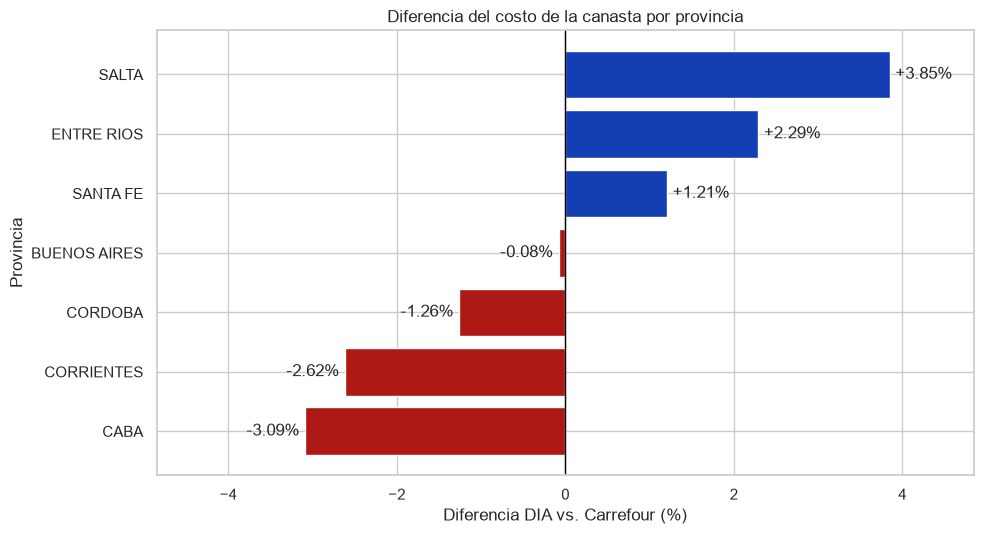

In [73]:
# Diferencia porcentual de la canasta por provincia
datos = df_costos_prov.sort_values('diferencia_pct')
colores = [COLOR_CARREFOUR if valor > 0 else COLOR_DIA
           for valor in datos['diferencia_pct']]

fig, ax = plt.subplots(figsize=(10, 5.5))

barras = ax.barh(datos.index, datos['diferencia_pct'], color=colores)

ax.bar_label(barras, fmt='%+.2f%%', padding=4)
ax.axvline(0, color='black', linewidth=1)
limite = datos['diferencia_pct'].abs().max() + 1
ax.set_xlim(-limite, limite)
ax.set_title('Diferencia del costo de la canasta por provincia')
ax.set_xlabel('Diferencia DIA vs. Carrefour (%)')
ax.set_ylabel('Provincia')

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_diferencia_canasta_provincias.png', dpi=200, bbox_inches='tight')
plt.show()

La comparación de la misma canasta de **33 productos en las siete provincias** muestra diferencias territoriales entre ambas cadenas.

**DIA presenta un menor costo en cuatro provincias:** CABA (-3,09%), Corrientes (-2,62%), Córdoba (-1,26%) y Buenos Aires (-0,08%). En esta última, la diferencia es prácticamente nula.

Por su parte, **Carrefour presenta un menor costo en tres provincias:** Salta (+3,85%), Entre Ríos (+2,29%) y Santa Fe (+1,21%).

La canasta de menor costo dentro de DIA se registra en Córdoba y Santa Fe ($145.949,00), mientras que en Carrefour corresponde a Entre Ríos ($142.706,07).

Los resultados evidencian que **la cadena con menor costo depende de la provincia analizada**, aun utilizando exactamente los mismos productos y cantidades comerciales.

Esta comparación utiliza precios efectivos medios por producto, provincia y cadena. Por lo tanto, los costos representan valores consolidados y no necesariamente los precios disponibles en una única sucursal.

## 6. ¿Qué productos explican las diferencias?

Se calcula cuánto aporta cada producto a la diferencia de costo de la canasta. Una diferencia negativa indica que el artículo es más barato en DIA; una positiva, que es más barato en Carrefour.

El impacto monetario de un producto no es lo mismo que su diferencia porcentual: un producto de precio elevado puede influir más en la suma total.

In [74]:
df_canasta['diferencia_abs'] = df_canasta['precio_medio_dia'] - df_canasta['precio_medio_carrefour']
df_canasta['diferencia_pct'] = df_canasta['diferencia_abs'] / df_canasta['precio_medio_carrefour'] * 100

df_canasta['cadena_mas_barata'] = np.where(
    df_canasta['diferencia_abs'] < 0, 'DIA',
    np.where(df_canasta['diferencia_abs'] > 0, 'CARREFOUR', 'IGUAL')
)

print('Cantidad de productos más baratos en cada cadena:')
display(df_canasta['cadena_mas_barata'].value_counts())

# Los 10 artículos con mayor diferencia monetaria absoluta.
df_impacto = df_canasta.assign(
    impacto=df_canasta['diferencia_abs'].abs()
).sort_values('impacto', ascending=False)

display(df_impacto[[
    'descripcion_carrefour', 'precio_medio_dia', 'precio_medio_carrefour',
    'diferencia_abs', 'diferencia_pct'
]].head(10).round(2))

Cantidad de productos más baratos en cada cadena:


cadena_mas_barata
DIA          18
CARREFOUR    15
Name: count, dtype: int64

,descripcion_carrefour,precio_medio_dia,precio_medio_carrefour,diferencia_abs,diferencia_pct
18,QUESO CREMA LA SERENISIMA CLASICO POTE X 290 GRS,2590.00,3952.71,-1362.71,-34.48
26,ANTITRANSPIRANTE AERO ORIGINAL DOVE X 150 CC.,4929.00,5782.93,-853.93,-14.77
31,DETERGENTE ULTRA LIMON MAGISTRAL BOT X 500 CC,4281.54,4936.13,-654.59,-13.26
28,TOALLA FEM SUAVE DOBLE PROTEC ALWAYS XTRA X 16...,6294.31,5921.59,372.72,6.29
7,ACEITE GIRASOL NATURA PET X 1.5 LT,6880.94,6580.81,300.13,4.56
8,PURE DE TOMATE LA CAMPAGNOLA TETRA X 530 GRM,1165.00,1421.48,-256.48,-18.04
32,ROLLO DE COCINA CLASICO SUSSEX 3 X 50 PAN,2950.00,2700.97,249.03,9.22
9,TOMATE PERITA CUBETEADO ARCOR LATA X 400 GRS,1808.39,1592.02,216.37,13.59
10,AZUCAR MOLIDA SUPERIOR LEDESMA BOLSA X 1 KG,1400.00,1615.68,-215.68,-13.35
5,LENTEJAS SECAS REMOJADAS ARCOR LATA X 300 GRS,1749.23,1533.91,215.32,14.04


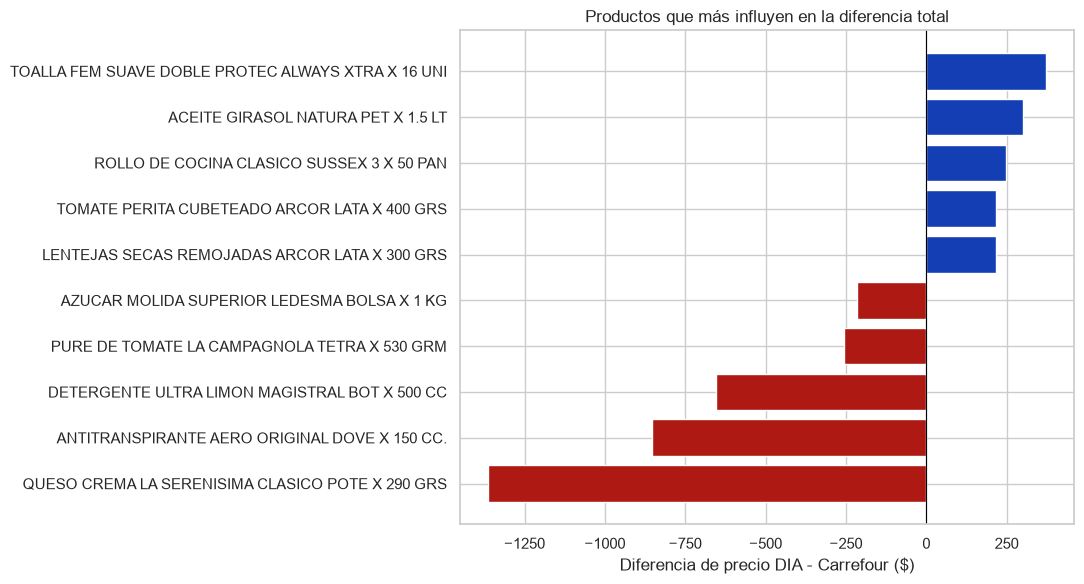

In [75]:
# Gráfico de los 10 productos con mayor impacto monetario
top_impacto = df_impacto.head(10).sort_values('diferencia_abs')

plt.figure(figsize=(11, 6))
plt.barh(
    top_impacto['descripcion_carrefour'],
    top_impacto['diferencia_abs'],
    color=[COLOR_CARREFOUR if valor > 0 else COLOR_DIA
           for valor in top_impacto['diferencia_abs']]
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Diferencia de precio DIA - Carrefour ($)')
plt.title('Productos que más influyen en la diferencia total')

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_productos_mayor_impacto.png', dpi=200, bbox_inches='tight')
plt.show()


En la canasta, **18 productos** presentan menor precio medio en DIA y **15** en Carrefour. Aunque las cantidades son relativamente similares, **la magnitud de las diferencias no es uniforme**.

Los mayores aportes favorables a DIA corresponden al **queso crema La Serenísima (-$1.362,71)**, el **antitranspirante Dove (-$853,93)** y el **detergente Magistral (-$654,59)**. En conjunto, sus diferencias suman **-$2.871,23**, una magnitud incluso superior a la diferencia final de la canasta (-$2.632,62), porque otros productos compensan parte de esa ventaja.

Entre los artículos favorables a Carrefour se destacan las **toallas femeninas Always (+$372,72)**, el **aceite Natura (+$300,13)** y el **rollo de cocina Sussex (+$249,03)**. Así, el costo total se explica por la combinación de ventajas y desventajas de precios de artículos específicos, y no solamente por cuál cadena resulta más barata en más productos.

## 7. Análisis de sensibilidad

Se recalcula la diferencia porcentual de la canasta quitando, de a uno, cada producto. Esto permite comprobar si el resultado depende demasiado de un artículo particular (*leave-one-out*).

No se modifica la selección original: son escenarios hipotéticos calculados a partir de la misma canasta.

In [76]:
# Excluir un artículo distinto en cada escenario, sin bucles ni funciones.
df_sensibilidad = df_canasta[['id_producto', 'descripcion_carrefour']].copy()
df_sensibilidad['diferencia_pct_sin_producto'] = (
    (costo_dia - df_canasta['precio_medio_dia'])
    - (costo_carrefour - df_canasta['precio_medio_carrefour'])
) / (costo_carrefour - df_canasta['precio_medio_carrefour']) * 100

print(f'Diferencia de la canasta completa: {diferencia_canasta_pct:+.2f}%')
print('Rango al excluir un producto:',
      f"{df_sensibilidad['diferencia_pct_sin_producto'].min():+.2f}% a",
      f"{df_sensibilidad['diferencia_pct_sin_producto'].max():+.2f}%")

display(df_sensibilidad.sort_values('diferencia_pct_sin_producto').round(2))

Diferencia de la canasta completa: -1.75%
Rango al excluir un producto: -2.08% a -0.87%


,id_producto,descripcion_carrefour,diferencia_pct_sin_producto
28,7500435229531,TOALLA FEM SUAVE DOBLE PROTEC ALWAYS XTRA X 16...,-2.08
7,7790272001029,ACEITE GIRASOL NATURA PET X 1.5 LT,-2.04
12,7793281493472,HAMBURGUESA DE CARNE UNION GANADERA X 4 UNI,-1.99
32,7790250056881,ROLLO DE COCINA CLASICO SUSSEX 3 X 50 PAN,-1.95
9,7790580567101,TOMATE PERITA CUBETEADO ARCOR LATA X 400 GRS,-1.91
5,7790580132453,LENTEJAS SECAS REMOJADAS ARCOR LATA X 300 GRS,-1.91
23,7509546686516,CREMA DENTAL TRIPLE ACCION COLGATE X 140 GRS,-1.91
22,7891150046481,JABON DE TOCADOR BLANCO DOVE 3 X 90 GRS,-1.89
29,7791290792036,JABON LIQUIDO P ROPA ECO LAVADO ALA MATIC X 3 LT,-1.87
24,7790740000264,SHAMPOO NUTRICION PLUSBELLE BOTELLA X 1LT,-1.85


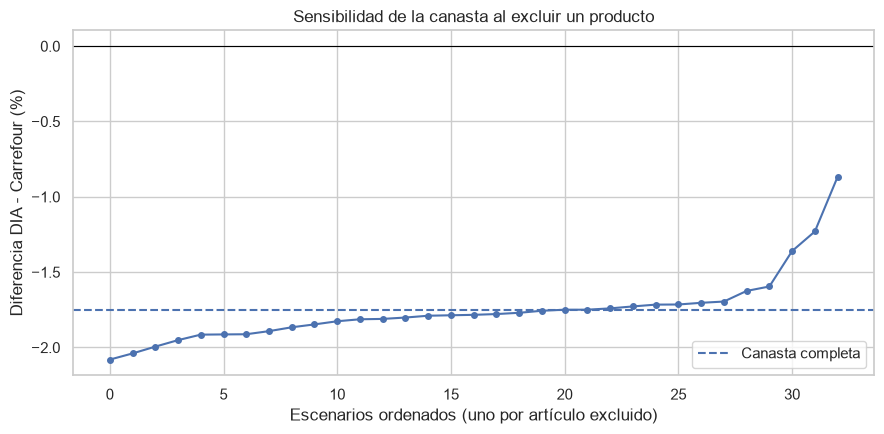

In [77]:
plt.figure(figsize=(9, 4.5))
plt.plot(
    df_sensibilidad['diferencia_pct_sin_producto'].sort_values().to_numpy(),
    marker='o', markersize=4
)
plt.axhline(diferencia_canasta_pct, linestyle='--', label='Canasta completa')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Escenarios ordenados (uno por artículo excluido)')
plt.ylabel('Diferencia DIA - Carrefour (%)')
plt.title('Sensibilidad de la canasta al excluir un producto')
plt.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_sensibilidad_canasta.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación del análisis de sensibilidad**

La diferencia de la canasta completa es de **-1,75 %** a favor de DIA. Al retirar **un producto distinto en cada uno de los 33 escenarios**, la diferencia oscila entre **-2,08 % y -0,87 %** y **no cambia de signo**.

La mayor reducción de la ventaja de DIA aparece al excluir el **queso crema La Serenísima** (diferencia restante de **-0,87 %**). En sentido inverso, al excluir las **toallas femeninas Always**, producto más barato en Carrefour, la ventaja de DIA aumenta hasta **-2,08 %**.

Por lo tanto, el resultado **no depende exclusivamente de la presencia de un único artículo**, aunque algunos productos influyen de manera importante. Este ejercicio solo estudia exclusiones individuales: no prueba que el resultado sea estable frente a otras canastas, modificaciones simultáneas o cantidades diferentes.

## 8. Integración de resultados de las etapas anteriores

Esta sección recupera resultados ya calculados en otros notebooks. **No se mezclan con el universo principal de la canasta.** Su función es contextualizar los hallazgos nuevos y mostrar el recorrido completo del proyecto.

- **Etapa 1:** precios efectivos, promociones y dispersión entre sucursales.
- **Etapa 2:** corrección de provincias y definición del territorio comparable.
- **Etapa 3:** comparación territorial, dispersión y ranking homogéneo de **1.662 productos en ocho provincias**.
- **Etapa 4:** cinco categorías y 400 etiquetas manuales.
- **Etapa 5:** categorización de los 1.820 artículos restantes mediante NLP/ML; Modelo 5 con **Macro F1 promedio de 0,911** en validación cruzada repetida.

Los datos históricos siguientes se transcriben de los resultados documentados; **no se recalculan con la canasta**.

### 8.1 Ranking provincial homogéneo — Etapa 3

Para el mismo conjunto de **1.662 productos de ocho provincias**, Carrefour registró una amplitud de **10,07 %** entre las provincias de menor y mayor precio medio (Jujuy y CABA). En DIA fue de **2,65 %** (Buenos Aires y Salta). Estos valores **no corresponden a la canasta de 33 artículos**.

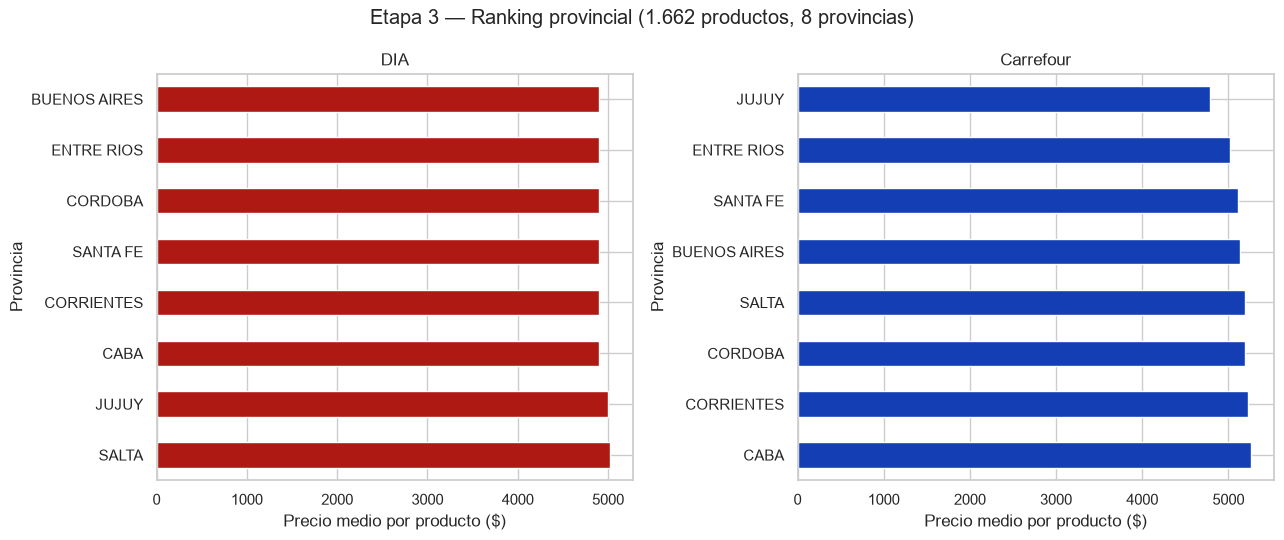

In [78]:
# Resultados documentados de la Etapa 3 (no provienen de la canasta).
ranking_8 = pd.DataFrame({
    'provincia': ['BUENOS AIRES', 'CABA', 'CORDOBA', 'CORRIENTES',
                  'ENTRE RIOS', 'JUJUY', 'SALTA', 'SANTA FE'],
    'DIA': [4894.96, 4901.24, 4895.50, 4895.99, 4895.07, 5000.19, 5024.45, 4895.71],
    'Carrefour': [5134.55, 5265.37, 5196.81, 5226.98, 5015.29, 4783.70, 5187.31, 5107.69]
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, cadena in zip(axes, ['DIA', 'Carrefour']):
    ranking_8.sort_values(cadena, ascending=False).plot.barh(
        x='provincia', y=cadena, ax=ax, legend=False, color=COLOR_DIA if cadena == 'DIA' else COLOR_CARREFOUR
    )
    ax.set_title(cadena)
    ax.set_xlabel('Precio medio por producto ($)')
    ax.set_ylabel('Provincia')

fig.suptitle('Etapa 3 — Ranking provincial (1.662 productos, 8 provincias)')
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_ranking_8_provincias.png', dpi=200, bbox_inches='tight')
plt.show()

### 8.2 Dispersión territorial — Etapa 3

Para los **2.220 productos comunes en siete provincias**, la mediana del rango porcentual territorial fue **3,61 % en DIA** y **9,21 % en Carrefour**. Es un indicador de variabilidad del precio de los mismos productos entre territorios, no una diferencia porcentual entre los costos de dos canastas.

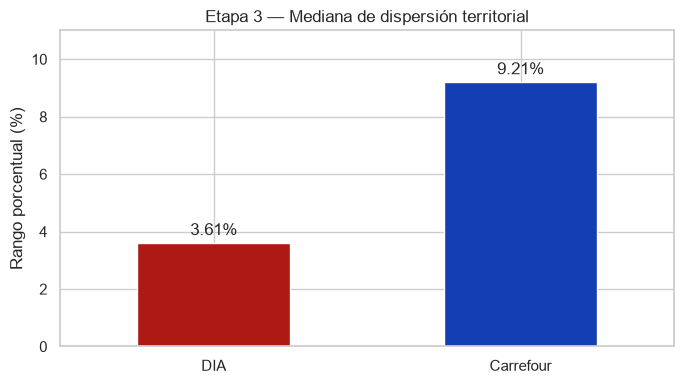

In [79]:
dispersion_etapa3 = pd.Series({'DIA': 3.61, 'Carrefour': 9.21})
ax = dispersion_etapa3.plot(kind='bar', figsize=(7, 4), rot=0, color=[COLOR_DIA, COLOR_CARREFOUR])
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3)
plt.title('Etapa 3 — Mediana de dispersión territorial')
plt.ylabel('Rango porcentual (%)')
plt.ylim(0, 11)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_dispersión_territorial.png', dpi=200, bbox_inches='tight')
plt.show()

### 8.3 Categorización automática — Etapas 4 y 5

La Etapa 4 generó **400 ejemplos etiquetados manualmente** y la Etapa 5 clasificó **1.820 productos adicionales**. Entre los modelos comparados por validación cruzada repetida, el **Modelo 5 (TF-IDF de palabras y caracteres + LinearSVC)** obtuvo el mayor Macro F1 promedio (**0,911**). Es una métrica de la clasificación de texto y **no mide el desempeño del análisis de precios**.

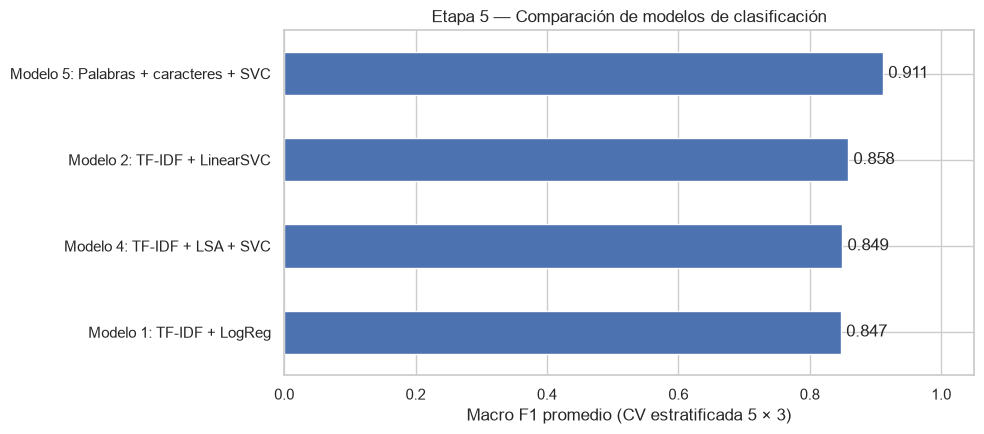

In [80]:
macro_f1_cv = pd.Series({
    'Modelo 1: TF-IDF + LogReg': 0.847,
    'Modelo 2: TF-IDF + LinearSVC': 0.858,
    'Modelo 4: TF-IDF + LSA + SVC': 0.849,
    'Modelo 5: Palabras + caracteres + SVC': 0.911
})
ax = macro_f1_cv.sort_values().plot(kind='barh', figsize=(10, 4.5))
ax.bar_label(ax.containers[0], fmt='%.3f', padding=4)
plt.xlim(0, 1.05)
plt.xlabel('Macro F1 promedio (CV estratificada 5 × 3)')
plt.title('Etapa 5 — Comparación de modelos de clasificación')
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'etapa6_comparacion_modelos.png', dpi=200, bbox_inches='tight')
plt.show()

**Lectura integrada de los hallazgos previos**

Los resultados recuperados permiten contextualizar la comparación final sin mezclar metodologías. En la **Etapa 3**, Carrefour presentó mayor dispersión territorial de precios de los mismos productos; el ranking homogéneo de ocho provincias mostró además una mayor amplitud entre provincias para esa cadena (**10,07 %**, frente al **2,65 %** de DIA). Ambos indicadores describen dimensiones distintas de la variabilidad territorial y **no miden el costo de la canasta de esta etapa**.

Las **etapas 4 y 5** aportaron la clasificación comercial de los 2.220 productos, a partir de 400 etiquetas manuales y 1.820 predicciones automáticas, lo que hizo posible comparar precios por categorías. El Macro F1 promedio de **0,911** del modelo seleccionado respalda su elección dentro del procedimiento de evaluación utilizado, sin garantizar que todas las categorías predichas sean correctas.

La Etapa 6 reúne estos aportes en dos escalas complementarias: el **universo completo de productos comparables** y una **canasta exploratoria de artículos específicos**. Sus resultados deben leerse por separado porque los conjuntos de productos y las preguntas de análisis no son los mismos.

## 9. Conclusiones generales

### 9.1 Comparación global del universo principal

La comparación de los **2.220 productos comunes de las siete provincias** muestra un precio medio por producto **aproximadamente de $5.102 en DIA y $5.416 en Carrefour**, con una diferencia cercana al **-5,79 %** a favor de DIA. Además, DIA presenta el menor precio en **1.330 artículos (59,91 %)**, frente a **890 (40,09 %)** favorables a Carrefour. Estos resultados corresponden a un promedio simple de precios consolidados por artículo y **no equivalen al costo de una canasta de consumo**.

### 9.2 Resultados de la comparación por categorías

Las categorías más numerosas (**ALIMENTOS, BEBIDAS y PERFUMERIA Y LIMPIEZA**) presentan precios medios inferiores en DIA, con diferencias de **-5,57 %, -8,03 % y -5,71 %**, respectivamente. En **MASCOTAS** y **OTROS**, los menores precios medios corresponden a Carrefour, aunque la cantidad de productos de estas categorías es reducida. La clasificación obtenida en las etapas 4 y 5 permitió incorporar esta dimensión comercial a la comparación sin utilizarla para definir la canasta.

### 9.3 Costo de la canasta exploratoria

La canasta de **33 productos seleccionados manualmente sin visualizar precios**, considerando **una unidad comercial de cada artículo**, alcanza un costo de **$147.749,30 en DIA** y **$150.381,92 en Carrefour**. La diferencia es de **$2.632,62 (-1,75 %)** a favor de DIA.

De los 33 artículos, **18** tienen un precio medio menor en DIA y **15** en Carrefour. Los mayores aportes monetarios a la ventaja de DIA provienen del **queso crema La Serenísima (-$1.362,71)**, el **antitranspirante Dove (-$853,93)** y el **detergente Magistral (-$654,59)**. En sentido contrario, Carrefour registra menores precios, entre otros, en las **toallas femeninas Always (+$372,72)** y el **aceite Natura (+$300,13)**.

La ventaja de DIA en la canasta (**-1,75 %**) es menor que la diferencia entre los precios medios del conjunto de **2.220 productos (aproximadamente -5,79 %)**. No se trata de resultados contradictorios: responden a **dos conjuntos de productos distintos** y no utilizan ponderaciones de consumo.

**Comparación territorial de la canasta**

La incorporación de la dimensión provincial permitió comprobar que la ventaja general de DIA, observada en el costo consolidado de la canasta (-1,75%), no se mantiene en todas las provincias.

Al comparar los mismos 33 productos en los siete territorios, DIA registra un menor costo en cuatro provincias y Carrefour en tres. Las mayores diferencias favorables a DIA aparecen en CABA (-3,09%) y Corrientes (-2,62%), mientras que Carrefour presenta sus mayores ventajas en Salta (+3,85%) y Entre Ríos (+2,29%).

Estos resultados refuerzan uno de los hallazgos centrales de la Etapa 3: **las diferencias de precios entre DIA y Carrefour presentan un componente territorial importante**.

La comparación consolidada y la provincial son complementarias, ya que utilizan distintos niveles de agregación de los precios medios. En consecuencia, los resultados no deben interpretarse como una ventaja comercial uniforme de una cadena en todos los territorios.

### 9.4 Sensibilidad y relación con las etapas previas

Al excluir individualmente cada producto de la canasta, la diferencia porcentual permanece negativa en los **33 escenarios**, con valores entre **-2,08 % y -0,87 %**. En consecuencia, la ventaja de DIA **no se revierte al eliminar un solo artículo**, aunque algunos productos tienen una influencia importante sobre su magnitud. Esto no garantiza que el mismo resultado se mantenga con otra selección de productos o cantidades.

Los resultados también son coherentes con los hallazgos descriptivos de la Etapa 3: Carrefour mostró mayor dispersión territorial de precios para los mismos productos (**9,21 % frente a 3,61 % en DIA**, como mediana del rango porcentual en siete provincias). El ranking provincial homogéneo de **1.662 productos en ocho provincias** confirmó diferencias territoriales de distinta amplitud entre cadenas. Esos resultados ofrecen contexto, pero **no se mezclaron en los cálculos nuevos de la Etapa 6**.

### 9.5 Alcance y limitaciones

- Los precios corresponden a **SEPA de julio de 2026** y son medias consolidadas por producto y cadena; no representan necesariamente precios disponibles juntos en una sucursal concreta.
- La canasta se eligió **intencionalmente** y sin visualizar los precios, lo que reduce un posible sesgo por conocimiento de las diferencias entre cadenas, pero no vuelve representativa la selección.
- Se consideró **una unidad comercial por artículo**, sin ponderaciones de consumo ni ajustes por necesidades de los hogares; **no constituye una canasta básica oficial**.
- Las cinco categorías incluyen predicciones automáticas de NLP/ML y pueden contener errores residuales. Los grupos más pequeños deben interpretarse con especial precaución.
- Se trata de **comparaciones descriptivas**, sin inferir causalidad ni generalizar automáticamente los resultados a otros períodos, sucursales o surtidos.

**Conclusión final:** en el universo y período analizados, DIA presenta menores precios medios en el conjunto general de productos y un menor costo para la canasta exploratoria seleccionada. La magnitud de la ventaja cambia según el enfoque —universo completo, categoría o canasta—, lo que demuestra la importancia de definir y documentar **qué productos, qué precios y qué agregación se comparan**.

## 10. Cierre y documentación

La Etapa 6 integra la comparación global de los **2.220 productos**, el análisis de las cinco categorías comerciales, una **canasta exploratoria de 33 artículos** y los principales hallazgos descriptivos de las etapas previas.

La selección de la canasta se conserva en `data/processed/canasta_seleccionada.xlsx`, con `id_producto` y `descripcion_carrefour`. Los precios se recuperan desde el Parquet final de la Etapa 5, sin copiarlos ni modificarlos manualmente.

La comparación provincial de la canasta confirma que los resultados generales deben interpretarse junto con la dimensión territorial, dado que la cadena de menor costo varía entre las siete provincias analizadas.

Las conclusiones anteriores se refieren al universo, fecha y metodología declarados y no deben interpretarse como precios actuales ni como un índice oficial de costo de vida.

### 10.1 Exportación de tablas de resultados

Como parte del cierre de la Etapa 6, se exportan las principales tablas de resultados en formato **CSV**, para facilitar su consulta, reutilización y trazabilidad.

Los archivos se guardan en la carpeta `outputs/tables/` e incluyen el resumen general de los 2.220 productos, la comparación por categorías, los precios de la canasta seleccionada, los costos provinciales y el análisis de sensibilidad.

Esta exportación permite conservar los resultados consolidados sin necesidad de ejecutar nuevamente todo el notebook y facilita su utilización en futuras visualizaciones o informes.

In [81]:
# 1. Resumen general de los 2.220 productos
resumen_global = pd.DataFrame([{
    'productos': len(df_productos),
    'precio_medio_dia': precio_general_dia,
    'precio_medio_carrefour': precio_general_carrefour,
    'diferencia_pct': diferencia_general_pct,
    'productos_mas_baratos_dia': dia_mas_barato,
    'productos_mas_baratos_carrefour': carrefour_mas_barato
}])

resumen_global.to_csv(RUTA_TABLAS / 'etapa6_resumen_general.csv', index=False, encoding='utf-8-sig')

# 2. Comparación por categorías
resumen_categorias.to_csv(RUTA_TABLAS / 'etapa6_resumen_categorias.csv', index=False, encoding='utf-8-sig')

# 3. Canasta de 33 productos con precios y diferencias
df_canasta.to_csv(RUTA_TABLAS / 'etapa6_canasta_con_precios.csv', index=False, encoding='utf-8-sig')

# 4. Costos de la canasta por provincia
df_costos_prov.reset_index().to_csv(RUTA_TABLAS / 'etapa6_costos_canasta_provincias.csv', index=False, encoding='utf-8-sig')

# 5. Análisis de sensibilidad
df_sensibilidad.to_csv(RUTA_TABLAS / 'etapa6_sensibilidad_canasta.csv', index=False, encoding='utf-8-sig')

print('Tablas de la Etapa 6 exportadas correctamente.')

Tablas de la Etapa 6 exportadas correctamente.
